# FINAL — iTransformer vs SA-LSTM (Copper, K=5) — Google Colab

**Thiết kế theo hình SA-LSTM mới và notebook `18-11-Copper_SA_LSTM_V22_Fresh_SA_WTI_Only_Kaggle(1).ipynb`, kết hợp iTransformer V20.**

**Cùng một bài toán:** dùng **22 phiên trước** của 5 biến **Aluminium, Tin, Silver, Gold, Copper_history** để dự báo **Copper(t)** (horizon 1). `Copper_history` chính là cột CSV `Copper` ở những phiên **t−22 ... t−1** — **không đưa Copper(t) vào đầu vào**. **Không dùng WTI**.

**So sánh có kiểm soát:**

- `naive`: Copper(t−1), không train.
- `itransformer_direct` / `itransformer_residual`: cùng kiến trúc iTransformer (5 variable tokens, 2 encoders, 4 heads); khác mục tiêu direct / sai phân.
- `sa_fixed_direct` / `sa_fixed_residual`: SA-LSTM Fixed với **LSTM(39) → Dropout(0.2) → LSTM(111) → Dense(32, ReLU) → Dropout(0.2) → Linear**, Adam 0.00005. Chế độ residual là **ablation bổ sung**, không phải mô hình direct đúng nghĩa trong hình.
- `sa_tuned_direct` / `sa_tuned_residual`: chính topology trên, nhưng **Simulated Annealing tìm units_1, units_2, learning rate** trên validation (riêng từng objective), **không dùng test**.

**Chú ý điểm lệch so với notebook SA-LSTM V22 cũ:** hình mới đặt Dropout thứ hai **sau Dense**; notebook gốc đặt **trước Dense**. Biến `SA_DROPOUT_LAYOUT='figure'` bên dưới **theo đúng hình**. Muốn tái hiện topology cũ, đổi `'notebook_v22'` (phải chạy mới vì kiến trúc đã đổi).

**Protocol:** chia thời gian, scaler fit train-only, chung train/validation/test timestamps, RAW input `(22,5)`, MSE, Adam, batch 64, early stopping patience 9, 4 split × 3 scheme (FULL); MAE/RMSE/MSE trên **đơn vị Copper gốc**, directional accuracy, naive skill, kiểm định HAC; mỗi job checkpoint riêng + trọng số `.keras` nếu bật.

> **Không có số liệu kết quả được nhúng sẵn.** Notebook sẽ yêu cầu `dataset_9_commodities_daily.csv`. Test ratios chồng lấn, không coi các hàng như kiểm định độc lập. Cùng input và mục tiêu mới là điều kiện cần, chứ chưa đủ để khẳng định kiến trúc nào tốt hơn do cách tìm HP và độ phức tạp mô hình khác nhau.


## 0. Cấu hình Colab — thay đổi ở cell này

- Để kiểm tra pipeline trong thời gian ngắn: đổi `MODE='QUICK_MODE'` (1 split × 1 scheme, 6 model fits + 1 Naive; SA search 2 trials/objective).
- Mặc định `FULL_MODE`: **4 ratios × 3 schemes × 6 model fits = 72 fits**, 12 Naive; **16 SA trials mỗi objective** (32 trials bổ sung). Máy T4 sẽ phù hợp hơn CPU, nhưng workload vẫn nặng.
- `SAVE_TO_DRIVE=True`: đặt checkpoint trên Google Drive, lần chạy lại sẽ bỏ qua các jobs đủ kết quả; run key khóa cấu hình và SHA-256 dataset.
- Để theo đúng code V22 SA-LSTM cũ về vị trí dropout (không theo hình): đặt `SA_DROPOUT_LAYOUT='notebook_v22'`.


In [2]:
from pathlib import Path
import os, sys, gc, time, json, math, shutil, zipfile, hashlib, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from scipy.stats import norm
import tensorflow as tf
from IPython.display import display

MODE = 'FULL_MODE'                     # 'FULL_MODE' hoặc 'QUICK_MODE'
SAVE_TO_DRIVE = True
PROJECT_NAME = 'Copper_iTransformer_vs_SA_LSTM_K5_Fair'
DATASET_NAME = 'dataset_9_commodities_daily.csv'
CUSTOM_CSV_PATH = ''                  # Ví dụ /content/drive/MyDrive/dataset_9_commodities_daily.csv
UPLOAD_IF_MISSING = True
EXPECTED_SHA256 = ''                  # Có thể khóa dataset; để trống nếu chưa biết
AUTO_DOWNLOAD_ZIP = False
SAVE_TRAINED_MODELS = True           # Lưu cả model.keras từng job trên Drive
INCLUDE_MODELS_IN_ZIP = False       # False để ZIP không quá lớn

# Khớp thứ tự hình: 4 kim loại + Copper_history (Copper quá khứ)
FEATURES = ['Aluminium', 'Tin', 'Silver', 'Gold', 'Copper']
TARGET = 'Copper'
LOOKBACK, HORIZON = 22, 1
SEED = 42
BATCH_SIZE = 64
RATIOS = (0.80, 0.90, 0.925, 0.95) if MODE == 'FULL_MODE' else (0.80,)
SCHEMES = ('expanding', 'rolling_756', 'recency_weighted') if MODE == 'FULL_MODE' else ('expanding',)
RECENCY_HALF_LIFE = 252
EPOCHS = 100 if MODE == 'FULL_MODE' else 2   # Cùng epoch budget cho hai kiến trúc
PATIENCE = 9 if MODE == 'FULL_MODE' else 1

# iTransformer theo sơ đồ V20: RAW, variable-wise attention
IT_LR = 3e-4
IT_EMBED, IT_HEADS, IT_HEAD_DIM, IT_FF, IT_ENCODERS = 48, 4, 12, 96, 2
IT_DROPOUT = 0.10
CLIPNORM = 1.0

# SA-LSTM: 39, 111, Dropout 0.2, Dense(32, relu), Output linear.
SA_FIXED_HP = {'units_1':39, 'units_2':111, 'learning_rate':5e-5}
SA_DROPOUT_LAYOUT = 'figure'         # 'figure' (sau Dense), 'notebook_v22' (trước Dense)
SA_DROPOUT = 0.20
SA_SEARCH_EVALS = 16 if MODE == 'FULL_MODE' else 2
SA_SEARCH_EPOCHS = 15 if MODE == 'FULL_MODE' else 2
SA_SEARCH_PATIENCE = 4 if MODE == 'FULL_MODE' else 1
SA_SEARCH_SEED = 2026
SA_TUNE_REF_RATIO = 0.80             # Chỉ 80/20 Expanding TRAIN/VAL, không sử dụng TEST
SA_SPACE = {'units_1':(16,96),'units_2':(24,160),'learning_rate':(1e-5,3e-3)}
OBJECTIVES = ('direct','residual')

assert MODE in ('FULL_MODE', 'QUICK_MODE')
assert SA_DROPOUT_LAYOUT in ('figure','notebook_v22')
assert len(FEATURES)==5 and len(set(FEATURES))==5 and TARGET in FEATURES
assert LOOKBACK==22 and HORIZON==1
try:
    import google.colab
    IN_COLAB=True
except ImportError:
    IN_COLAB=False
if IN_COLAB and SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT=Path('/content/drive/MyDrive') / PROJECT_NAME
elif IN_COLAB:
    PROJECT_ROOT=Path('/content') / PROJECT_NAME
else:
    PROJECT_ROOT=Path.cwd() / PROJECT_NAME
PROJECT_ROOT.mkdir(parents=True,exist_ok=True)
(PROJECT_ROOT/'data').mkdir(exist_ok=True)

tf.keras.utils.set_random_seed(SEED)
for gpu in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(gpu,True)
    except RuntimeError: pass
print('Platform:', 'Colab' if IN_COLAB else platform.platform())
print('TensorFlow',tf.__version__,'| GPUs',tf.config.list_physical_devices('GPU'))
print('Input:', FEATURES, '| Past-only Copper history; no WTI')
print('Mode:',MODE, '| Deep model fits:',len(RATIOS)*len(SCHEMES)*6,
      '| Naive:',len(RATIOS)*len(SCHEMES),'| SA search trials:',2*SA_SEARCH_EVALS)
print('Root:',PROJECT_ROOT)


Mounted at /content/drive
Platform: Colab
TensorFlow 2.21.0 | GPUs [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Input: ['Aluminium', 'Tin', 'Silver', 'Gold', 'Copper'] | Past-only Copper history; no WTI
Mode: FULL_MODE | Deep model fits: 72 | Naive: 12 | SA search trials: 32
Root: /content/drive/MyDrive/Copper_iTransformer_vs_SA_LSTM_K5_Fair


## 1. Nạp đúng CSV / khóa fingerprint / kiểm tra dữ liệu

Không lấy file kết quả/weights từ notebook WTI cũ. `Copper_history` **không phải cột riêng** trong CSV — đó là những giá trị lịch sử của cột `Copper`. Thiếu dữ liệu ở một trong năm biến thì bỏ phiên tương ứng; **không nội suy theo tương lai**. Khi lọc dòng, lookback 22 nghĩa là 22 quan sát hợp lệ liên tiếp.


In [3]:
from datetime import datetime
candidates = (
    ([Path(CUSTOM_CSV_PATH).expanduser()] if CUSTOM_CSV_PATH.strip() else [])
    + [PROJECT_ROOT/'data'/DATASET_NAME,
       Path('/content')/DATASET_NAME,
       Path('/content/drive/MyDrive')/DATASET_NAME,
       Path.cwd()/DATASET_NAME,
       Path('data/processed')/DATASET_NAME,
       Path('data/raw')/DATASET_NAME]
)
data_path = next((p for p in candidates if p.is_file()),None)
if data_path is None and IN_COLAB and UPLOAD_IF_MISSING:
    print('Chưa tìm thấy CSV. Vui lòng upload:',DATASET_NAME)
    from google.colab import files
    uploaded = files.upload()
    if DATASET_NAME not in uploaded:
        raise FileNotFoundError('Tên CSV được upload chưa đúng: '+repr(list(uploaded)))
    data_path=Path('/content')/DATASET_NAME
if data_path is None:
    raise FileNotFoundError('Không tìm thấy CSV: '+DATASET_NAME+'; sửa CUSTOM_CSV_PATH nếu cần.')

csv_sha256=hashlib.sha256(data_path.read_bytes()).hexdigest()
if EXPECTED_SHA256 and csv_sha256.lower()!=EXPECTED_SHA256.lower():
    raise RuntimeError('SHA-256 CSV khác dữ liệu đã khóa: '+csv_sha256)
persistent_csv=PROJECT_ROOT/'data'/DATASET_NAME
if IN_COLAB and SAVE_TO_DRIVE and data_path.resolve()!=persistent_csv.resolve():
    if persistent_csv.exists():
        if hashlib.sha256(persistent_csv.read_bytes()).hexdigest()!=csv_sha256:
            raise RuntimeError('Drive có dataset khác SHA-256, hãy đổi PROJECT_NAME hoặc kiểm tra CSV.')
    else:
        shutil.copy2(data_path,persistent_csv)
    data_path=persistent_csv

raw=pd.read_csv(data_path)
required=['Date']+FEATURES
missing_cols=sorted(set(required)-set(raw.columns))
if missing_cols: raise KeyError('CSV thiếu các cột: '+repr(missing_cols))
raw['Date']=pd.to_datetime(raw['Date'],errors='coerce')
if raw['Date'].isna().any() or raw['Date'].duplicated().any():
    raise ValueError('Date có NaT hoặc trùng; kiểm tra CSV trước khi chạy.')
for c in FEATURES: raw[c]=pd.to_numeric(raw[c],errors='coerce')
raw=raw.sort_values('Date').reset_index(drop=True)
quality=pd.DataFrame({'column':required,
    'missing': [int(raw[c].isna().sum()) for c in required],
    'dtype':[str(raw[c].dtype) for c in required]})
data=raw.dropna(subset=FEATURES).reset_index(drop=True)
if len(data)<1000: raise ValueError('Dữ liệu sau làm sạch quá ít (<1000 quan sát).')
if not np.isfinite(data[FEATURES].to_numpy(dtype=float)).all():
    raise ValueError('Giá có NaN/Inf sau lọc.')
if not (data[FEATURES]>0).to_numpy().all():
    raise ValueError('Có giá không dương — kiểm tra dataset trước khi huấn luyện.')

config={
 'version':'fair_itransformer_sa_lstm_k5_v1','mode':MODE,'dataset_sha256':csv_sha256,
 'features':FEATURES,'target':TARGET,'lookback':LOOKBACK,'horizon':HORIZON,
 'seed':SEED,'batch':BATCH_SIZE,'ratios':RATIOS,'schemes':SCHEMES,
 'half_life':RECENCY_HALF_LIFE,'epochs':EPOCHS,'patience':PATIENCE,
 'it_lr':IT_LR,'it_arch':[IT_EMBED,IT_HEADS,IT_HEAD_DIM,IT_FF,IT_ENCODERS,IT_DROPOUT],
 'sa_fixed_hp':SA_FIXED_HP,'sa_dropout_layout':SA_DROPOUT_LAYOUT,'sa_dropout':SA_DROPOUT,
 'sa_search_evals':SA_SEARCH_EVALS,'sa_search_epochs':SA_SEARCH_EPOCHS,
 'sa_search_patience':SA_SEARCH_PATIENCE,'sa_search_seed':SA_SEARCH_SEED,
 'sa_search_ref_ratio':SA_TUNE_REF_RATIO,'sa_space':SA_SPACE,'objectives':OBJECTIVES,
 'clipnorm':CLIPNORM
}
config_hash=hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()[:12]
RUN_KEY=f'{MODE}_K5_lb22_s{SEED}_data{csv_sha256[:8]}_cfg{config_hash}'
OUT=PROJECT_ROOT/'itransformer_vs_sa_lstm' / RUN_KEY
(OUT/'jobs').mkdir(parents=True,exist_ok=True)
(OUT/'sa_search').mkdir(parents=True,exist_ok=True)
(OUT/'figures').mkdir(parents=True,exist_ok=True)
(OUT/'config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
quality.to_csv(OUT/'data_quality.csv',index=False)
print('Dataset:',data_path,'| SHA256:',csv_sha256)
print('N rows:',len(data),'| date range:',data.Date.min().date(),data.Date.max().date())
print('Dropped:',len(raw)-len(data),'| Output:',OUT)
display(quality)


Chưa tìm thấy CSV. Vui lòng upload: dataset_9_commodities_daily.csv


Saving dataset_9_commodities_daily.csv to dataset_9_commodities_daily.csv
Dataset: /content/drive/MyDrive/Copper_iTransformer_vs_SA_LSTM_K5_Fair/data/dataset_9_commodities_daily.csv | SHA256: a761a9082de36ad8724597ff1518e24bbf1a61676bd3164676e7f4218d275d83
N rows: 2710 | date range: 2016-01-13 2026-11-13
Dropped: 0 | Output: /content/drive/MyDrive/Copper_iTransformer_vs_SA_LSTM_K5_Fair/itransformer_vs_sa_lstm/FULL_MODE_K5_lb22_s42_dataa761a908_cfgd1b751120e44


,column,missing,dtype
0,Date,0,datetime64[ns]
1,Aluminium,0,float64
2,Tin,0,float64
3,Silver,0,float64
4,Gold,0,float64
5,Copper,0,float64


## 2. Tách train/validation/test chung cho cả hai kiến trúc (không leakage)

Đối với từng `ratio`/`scheme`, scaler X (5 biến) và Y (Copper) chỉ **fit trên train** `[fit_start, val_start)`. Validation là **10% cuối phần trước test**. Test: `[int(n×ratio),n)`. `rolling_756`: train 756 phiên tính đến đầu validation; `recency_weighted`: vẫn expanding nhưng trọng số train giảm theo half-life=252. Test có thể dùng 22 phiên gần nhất từ trước test — đó là ngữ cảnh lịch sử hợp lệ.


In [4]:
def make_context(frame,ratio,scheme):
    if scheme not in SCHEMES: raise ValueError(scheme)
    n=len(frame)
    split=int(n*float(ratio))
    val_start=int(split*0.90)
    fit_start=max(0,val_start-756) if scheme=='rolling_756' else 0
    if not (LOOKBACK+40 < val_start-fit_start and val_start<split<n):
        raise ValueError('Split quá ngắn cho lookback/validation/test')
    xsc=MinMaxScaler().fit(frame.iloc[fit_start:val_start][FEATURES])
    ysc=MinMaxScaler().fit(frame.iloc[fit_start:val_start][[TARGET]])
    x_all=xsc.transform(frame[FEATURES]).astype('float32')
    y_all=ysc.transform(frame[[TARGET]]).ravel().astype('float32')
    copper_idx=FEATURES.index(TARGET)
    def make_block(start,end,train=False):
        ids=np.arange(max(start,LOOKBACK),end,dtype=np.int64)
        if train: ids=ids[ids-LOOKBACK>=fit_start]
        if not len(ids): raise ValueError('Không có sliding windows cho '+str((start,end)))
        windows=ids[:,None]-LOOKBACK+np.arange(LOOKBACK)[None,:]
        if not np.all(windows < ids[:,None]): raise AssertionError('Phát hiện future leakage')
        return {'idx':ids, 'X':x_all[windows],
                'y':y_all[ids],'prev':y_all[ids-1],
                'date':frame.Date.iloc[ids].to_numpy()}
    tr=make_block(fit_start,val_start,train=True)
    va=make_block(val_start,split)
    te=make_block(split,n)
    assert tr['idx'][-1] < va['idx'][0] < te['idx'][0]
    assert tr['X'].shape[1:] == (LOOKBACK,len(FEATURES))
    assert np.allclose(te['X'][:,-1,copper_idx],te['prev'],atol=2e-6)
    assert xsc.n_samples_seen_==val_start-fit_start
    return {'train':tr,'val':va,'test':te,'xsc':xsc,'ysc':ysc,
            'ratio':float(ratio),'scheme':scheme,'fit_start':fit_start,
            'val_start':val_start,'test_start':split,
            'features':FEATURES}

ctx_check=make_context(data,RATIOS[0],SCHEMES[0])
for splitname in ['train','val','test']:
    x=ctx_check[splitname]
    print(splitname,'X',x['X'].shape,'Y',x['y'].shape,
          't=',str(pd.Timestamp(x['date'][0]).date()),'...',str(pd.Timestamp(x['date'][-1]).date()))
assert not any('WTI'==c for c in FEATURES)
print('PASS: same 5 RAW input channels, history only, train-fitted scalers.')


train X (1929, 22, 5) Y (1929,) t= 2016-02-16 ... 2023-12-06
val X (217, 22, 5) Y (217,) t= 2023-12-07 ... 2024-10-04
test X (542, 22, 5) Y (542,) t= 2024-10-07 ... 2026-11-13
PASS: same 5 RAW input channels, history only, train-fitted scalers.


## 3. Kiến trúc: iTransformer V20 và SA-LSTM theo hình

**iTransformer:** đảo trục `(22,5)→(5,22)`, mỗi token là lịch sử của một biến → Dense embedding 48 → 2 Encoder (attention 4 heads giữa 5 token) → Flatten → Dense32/GELU → Dropout 0.1 → Linear. **SA-LSTM:** 2 lớp LSTM, 2 Dropout0.2, Dense32/ReLU và Linear như hình. SA chỉ điều chỉnh units và LR; output vẫn tuyến tính. Cả hai tối ưu **MSE** theo objective được lựa chọn.


In [5]:
def build_itransformer(input_shape=(LOOKBACK,5)):
    inp=tf.keras.Input(shape=input_shape,name='prices_22x5')
    x=tf.keras.layers.Permute((2,1),name='inverted_variable_tokens')(inp)
    x=tf.keras.layers.Dense(IT_EMBED,name='variable_embedding')(x)
    for i in range(IT_ENCODERS):
        a=tf.keras.layers.MultiHeadAttention(
            num_heads=IT_HEADS,key_dim=IT_HEAD_DIM,dropout=IT_DROPOUT,
            name=f'encoder{i+1}_mha')(x,x)
        a=tf.keras.layers.Dropout(IT_DROPOUT,name=f'encoder{i+1}_attn_dropout')(a)
        x=tf.keras.layers.LayerNormalization(epsilon=1e-6,name=f'encoder{i+1}_attention_norm')(x+a)
        y=tf.keras.layers.Dense(IT_FF,activation='gelu',name=f'encoder{i+1}_ff1')(x)
        y=tf.keras.layers.Dropout(IT_DROPOUT,name=f'encoder{i+1}_ff_dropout')(y)
        y=tf.keras.layers.Dense(IT_EMBED,name=f'encoder{i+1}_ff2')(y)
        x=tf.keras.layers.LayerNormalization(epsilon=1e-6,name=f'encoder{i+1}_ff_norm')(x+y)
    x=tf.keras.layers.Flatten(name='flatten_5x48')(x)
    x=tf.keras.layers.Dense(32,activation='gelu',name='forecast_head')(x)
    x=tf.keras.layers.Dropout(IT_DROPOUT,name='head_dropout')(x)
    out=tf.keras.layers.Dense(1,activation='linear',name='copper_forecast')(x)
    model=tf.keras.Model(inp,out,name='iTransformer_K5')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=IT_LR,clipnorm=CLIPNORM),loss='mse')
    return model

def build_sa_lstm(hp=None,input_shape=(LOOKBACK,5)):
    hp=dict(SA_FIXED_HP if hp is None else hp)
    u1,u2=int(hp['units_1']),int(hp['units_2'])
    lr=float(hp['learning_rate'])
    inp=tf.keras.Input(shape=input_shape,name='prices_22x5')
    x=tf.keras.layers.LSTM(u1,return_sequences=True,
              activation='tanh',recurrent_activation='sigmoid',name='lstm_1')(inp)
    x=tf.keras.layers.Dropout(SA_DROPOUT,name='dropout_1')(x)
    x=tf.keras.layers.LSTM(u2,activation='tanh',
              recurrent_activation='sigmoid',name='lstm_2')(x)
    if SA_DROPOUT_LAYOUT=='notebook_v22':
        x=tf.keras.layers.Dropout(SA_DROPOUT,name='dropout_2')(x)
    x=tf.keras.layers.Dense(32,activation='relu',name='dense_relu')(x)
    if SA_DROPOUT_LAYOUT=='figure':
        x=tf.keras.layers.Dropout(SA_DROPOUT,name='dropout_2')(x)
    out=tf.keras.layers.Dense(1,activation='linear',name='copper_forecast')(x)
    model=tf.keras.Model(inp,out,name='SA_LSTM')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr,clipnorm=CLIPNORM),loss='mse')
    return model

for name,builder in [('iTransformer',build_itransformer),('SA-LSTM Fixed',build_sa_lstm)]:
    tf.keras.backend.clear_session()
    net=builder()
    assert net.input_shape==(None,22,5) and net.output_shape==(None,1)
    print(name,'| input:',net.input_shape,'| params:',net.count_params())
    if name=='iTransformer':
        assert net.get_layer('variable_embedding').output.shape[-2:]==(5,48)
    else:
        assert net.get_layer('lstm_1').units==39 and net.get_layer('lstm_2').units==111
    del net
print('PASS: 5-feature input, scalar output, architecture checks')
tf.keras.backend.clear_session();gc.collect()


iTransformer | input: (None, 22, 5) | params: 46769
SA-LSTM Fixed | input: (None, 22, 5) | params: 77681
PASS: 5-feature input, scalar output, architecture checks


0

## 4. Train, MAE/RMSE/MSE, Directional Accuracy, residual audit và checkpoint

**Direct:** target là giá Copper đã chuẩn hóa. **Residual:** target là `(Copper(t)−Copper(t−1))` trên cùng thang Y đã chuẩn hóa, và dự báo cuối cùng là `Copper(t−1)+Δ`. Đánh giá luôn inverse-transform về **giá gốc**, không lấy MAE ở thang khác để so sánh.

Một mô hình chỉ được đánh dấu hoàn thành khi lưu đủ `predictions.csv` và `metrics.csv` hợp lệ. Bật `SAVE_TRAINED_MODELS` để lưu thêm model `.keras` từng job; không trộn CSV metadata khác schema.


In [6]:
def reset_net(seed=SEED):
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(int(seed))

def sample_weights(n,scheme):
    if scheme!='recency_weighted': return None
    ages=np.arange(n-1,-1,-1,dtype=np.float64)
    w=np.exp(-np.log(2)*ages/RECENCY_HALF_LIFE)
    return (w/w.mean()).astype('float32')

def targets(block,objective):
    if objective=='direct': return block['y']
    if objective=='residual': return block['y']-block['prev']
    raise ValueError(objective)

def restore_price_preds(block,preds,objective):
    vals=np.asarray(preds,dtype=np.float64).reshape(-1)
    return (block['prev']+vals) if objective=='residual' else vals

def to_raw(ctx,values):
    return ctx['ysc'].inverse_transform(np.asarray(values,dtype=np.float64).reshape(-1,1)).ravel()

def atomic_csv(df,path):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp')
    df.to_csv(tmp,index=False)
    os.replace(tmp,path)

def atomic_json(obj,path):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp')
    tmp.write_text(json.dumps(obj,ensure_ascii=False,indent=2),encoding='utf-8')
    os.replace(tmp,path)

def fit_predict(ctx,architecture,objective,hp=None,seed=SEED,epochs=EPOCHS,
                patience=PATIENCE,skip_test=False,save_model_path=None):
    reset_net(seed)
    net=build_itransformer() if architecture=='itransformer' else build_sa_lstm(hp)
    tr,va,te=ctx['train'],ctx['val'],ctx['test']
    weights=sample_weights(len(tr['idx']),ctx['scheme'])
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=patience,
               restore_best_weights=True)]
    t0=time.monotonic()
    history=net.fit(tr['X'],targets(tr,objective),
                    validation_data=(va['X'],targets(va,objective)),
                    sample_weight=weights,epochs=epochs,batch_size=BATCH_SIZE,
                    shuffle=False,callbacks=callbacks,verbose=0)
    raw_va=net.predict(va['X'],verbose=0).reshape(-1)
    pred_va=restore_price_preds(va,raw_va,objective)
    pred_te=None
    if not skip_test:
        raw_te=net.predict(te['X'],verbose=0).reshape(-1)
        pred_te=restore_price_preds(te,raw_te,objective)
    if save_model_path is not None:
        path=Path(save_model_path)
        path.parent.mkdir(parents=True,exist_ok=True)
        # Keras 3 yêu cầu đuôi .keras, lưu tạm để tránh file checkpoint dở dang.
        temp=path.with_name(path.stem+'.tmp.keras')
        net.save(str(temp))
        os.replace(temp,path)
    elapsed=time.monotonic()-t0
    h=pd.DataFrame({'epoch':np.arange(1,len(history.history['loss'])+1),
                    'loss':history.history['loss'], 'val_loss':history.history['val_loss']})
    extras={'epochs_run':len(h),'best_epoch':int(np.argmin(h['val_loss'])+1),
            'fit_seconds':float(elapsed),'params':int(net.count_params())}
    del net
    reset_net(seed)
    return pred_va,pred_te,extras,h

def score_job(ctx,model_name,pv,pt,extra=None):
    va,te=ctx['val'],ctx['test']
    y=to_raw(ctx,te['y']);yp=to_raw(ctx,pt);base=to_raw(ctx,te['prev'])
    vy=to_raw(ctx,va['y']);vyp=to_raw(ctx,pv)
    ae=np.abs(y-yp);na=np.abs(y-base)
    dp=yp-base;dt=y-base
    stdp=float(np.std(dp));stdt=float(np.std(dt))
    corr=float(np.corrcoef(dp,dt)[0,1]) if stdp>1e-12 and stdt>1e-12 else np.nan
    mae=float(ae.mean());bmae=float(na.mean())
    row={
     'model':model_name,'ratio':ctx['ratio'],'scheme':ctx['scheme'],
     'seed':SEED,'n_train':len(ctx['train']['idx']),'n_val':len(va['idx']),'n_test':len(te['idx']),
     'mae':mae,'rmse':float(np.sqrt(np.mean((y-yp)**2))),
     'mse':float(np.mean((y-yp)**2)),'mae_naive':bmae,
     'mae_improvement_pct':float(100*(bmae-mae)/bmae) if bmae>0 else np.nan,
     'directional_accuracy_pct':float(100*np.mean(np.sign(dp)==np.sign(dt))),
     'val_mae_raw':float(np.mean(np.abs(vy-vyp))),
     'val_mse_raw':float(np.mean((vy-vyp)**2)),
     'delta_pred_std_raw':stdp,'delta_true_std_raw':stdt,
     'pred_delta_corr':corr,'pred_delta_mean_abs_raw':float(np.abs(dp).mean()),
     'fit_start_date':str(data.Date.iloc[ctx['fit_start']].date()),
     'train_fit_end_date':str(data.Date.iloc[ctx['val_start']-1].date()),
     'test_start_date':str(pd.Timestamp(te['date'][0]).date()),
     'test_end_date':str(pd.Timestamp(te['date'][-1]).date()),
     'run_key':RUN_KEY}
    row.update(extra or {})
    p=pd.DataFrame({'Date':te['date'],'ratio':ctx['ratio'],'scheme':ctx['scheme'],
       'model':model_name,'seed':SEED,'run_key':RUN_KEY,
       'actual':y,'pred':yp,'naive':base,
       'actual_delta':dt,'pred_delta':dp,
       'absolute_error':ae,'naive_absolute_error':na})
    return row,p

MODEL_NAMES=('naive','itransformer_direct','itransformer_residual',
             'sa_fixed_direct','sa_fixed_residual','sa_tuned_direct','sa_tuned_residual')

def job_folder(ratio,scheme,model):
    return OUT/'jobs'/f'r{round(ratio*1000):04d}_{scheme}_{model}_s{SEED}'

def valid_checkpoint(folder,expected_test_n,model):
    mp=folder/'metrics.csv';pp=folder/'predictions.csv'
    if not(mp.is_file() and pp.is_file()): return False
    try:
        m=pd.read_csv(mp);p=pd.read_csv(pp)
        return (len(m)==1 and len(p)==expected_test_n
            and m.iloc[0]['run_key']==RUN_KEY and m.iloc[0]['model']==model
            and (p['run_key']==RUN_KEY).all() and (p['model']==model).all()
            and {'Date','actual','pred','naive'}.issubset(p.columns)
            and not p['Date'].duplicated().any()
            and np.isfinite(p[['actual','pred','naive']].to_numpy(float)).all())
    except Exception:
        return False

def run_job(ctx,model,sa_best):
    folder=job_folder(ctx['ratio'],ctx['scheme'],model)
    exp_n=len(ctx['test']['idx'])
    if valid_checkpoint(folder,exp_n,model):
        m=pd.read_csv(folder/'metrics.csv').iloc[0]
        print(f'[SKIP] {model:24s} ratio={ctx["ratio"]:.3f} {ctx["scheme"]:18s} MAE={m.mae:.6f}',flush=True)
        return
    folder.mkdir(parents=True,exist_ok=True)
    if model=='naive':
        pv,pt=ctx['val']['prev'],ctx['test']['prev']
        extra={'epochs_run':0,'best_epoch':0,'fit_seconds':0.,'params':0,'hp_json':'{}'}
        history=None
    else:
        arch='itransformer' if model.startswith('itransformer') else 'sa_lstm'
        objective='residual' if model.endswith('residual') else 'direct'
        hp=(SA_FIXED_HP if model.startswith('sa_fixed') else
            sa_best[objective] if model.startswith('sa_tuned') else None)
        model_path=folder/'model.keras' if SAVE_TRAINED_MODELS else None
        pv,pt,extra,history=fit_predict(ctx,arch,objective,hp,save_model_path=model_path)
        extra['hp_json']=json.dumps(hp) if hp else json.dumps({'learning_rate':IT_LR})
    row,pred=score_job(ctx,model,pv,pt,extra)
    # metrics.csv LAST -> committed only after predictions/history/models persisted
    atomic_csv(pred,folder/'predictions.csv')
    if history is not None: atomic_csv(history,folder/'history.csv')
    atomic_csv(pd.DataFrame([row]),folder/'metrics.csv')
    print(f'[DONE] {model:24s} ratio={ctx["ratio"]:.3f} {ctx["scheme"]:18s} '
          f'MAE={row["mae"]:.6f} | Naive skill={row["mae_improvement_pct"]:+.3f}% '
          f'| epochs={int(row["epochs_run"])}',flush=True)


## 5. Fresh Simulated Annealing (SA) — chỉ học trên train/validation

Mỗi **objective** (`direct` và `residual`) có một đợt SA riêng, tránh dùng HP tối ưu cho direct rồi gọi đó là tối ưu cho residual. Reference là **80/20 Expanding**, SA fit scaler trên training trước validation; **không hề đọc Y test để chọn HP**. State lưu sau mỗi trial, hỗ trợ resume. Các HP Fixed 39/111/5e−5 là đối chứng, **không mặc định xem 39/111 là optimum của 5 biến mới**.


In [7]:
def sa_clip(h):
    return {'units_1':int(np.clip(round(h['units_1']),*SA_SPACE['units_1'])),
            'units_2':int(np.clip(round(h['units_2']),*SA_SPACE['units_2'])),
            'learning_rate':float(np.clip(h['learning_rate'],*SA_SPACE['learning_rate']))}

def sa_neighbor(h,rng):
    x=dict(h)
    dimension=str(rng.choice(['units_1','units_2','learning_rate']))
    if dimension=='learning_rate':
        x[dimension]=float(x[dimension]*np.exp(rng.normal(0,0.65)))
    else:
        x[dimension]=int(x[dimension]+int(rng.choice([-1,1]))*int(rng.choice([8,16,24])))
    return sa_clip(x)

def sa_search(objective):
    folder=OUT/'sa_search';folder.mkdir(exist_ok=True)
    state_file=folder/f'sa_state_{objective}.json'
    trials_file=folder/f'sa_trials_{objective}.csv'
    rng=np.random.default_rng(SA_SEARCH_SEED+(0 if objective=='direct' else 1000))
    state={'objective':objective,'run_key':RUN_KEY,'current':sa_clip(SA_FIXED_HP),
           'best':sa_clip(SA_FIXED_HP),'current_loss':None,'best_loss':None,
           'trials':[],'rng_state':rng.bit_generator.state}
    if state_file.exists():
        saved=json.loads(state_file.read_text(encoding='utf-8'))
        if saved.get('run_key') != RUN_KEY or saved.get('objective') != objective:
            raise RuntimeError('SA state của một cấu hình khác: '+str(state_file))
        state=saved
        rng.bit_generator.state=state['rng_state']
    ctx=make_context(data,SA_TUNE_REF_RATIO,'expanding')
    if len(state['trials'])>SA_SEARCH_EVALS:
        raise RuntimeError('SA state có nhiều trials hơn budget, hãy kiểm tra.')
    for k in range(len(state['trials']),SA_SEARCH_EVALS):
        temp=max(0.05,0.88**k)
        proposal=dict(state['current']) if k==0 else sa_neighbor(state['current'],rng)
        pv,_,info,_=fit_predict(ctx,'sa_lstm',objective,hp=proposal,
             seed=SA_SEARCH_SEED+k+(0 if objective=='direct' else 1000),
             epochs=SA_SEARCH_EPOCHS,patience=SA_SEARCH_PATIENCE,skip_test=True)
        score=float(np.mean((pv-ctx['val']['y'])**2))
        if not np.isfinite(score): raise RuntimeError('SA non-finite validation MSE')
        old_score=state['current_loss'] if state['current_loss'] is not None else np.inf
        effective_temp=max(1e-8,temp*max(score,old_score if np.isfinite(old_score) else score,1e-5))
        accept=(score<=old_score) or bool(rng.random() < np.exp(-(score-old_score)/effective_temp))
        if accept:
            state['current'],state['current_loss']=dict(proposal),score
        if state['best_loss'] is None or score<float(state['best_loss']):
            state['best'],state['best_loss']=dict(proposal),score
        state['trials'].append({
          'objective':objective,'trial':k+1,'temperature':float(temp),
          'val_mse_scaled':score,'accepted':bool(accept),
          'best_val_mse_scaled':state['best_loss'],'epochs_run':info['epochs_run'],
          'fit_seconds':info['fit_seconds'],**proposal})
        state['rng_state']=rng.bit_generator.state
        atomic_json(state,state_file)
        atomic_csv(pd.DataFrame(state['trials']),trials_file)
        print(f'[SA {objective} {k+1:02d}/{SA_SEARCH_EVALS}] '
              f'valMSE={score:.7f} best={state["best_loss"]:.7f} '
              f'accepted={accept} hp={proposal}',flush=True)
    print('SA COMPLETE',objective, 'best HP',state['best'], 'best validation loss',state['best_loss'])
    return state['best']

sa_best={obj:sa_search(obj) for obj in OBJECTIVES}
atomic_json({'reference_ratio':SA_TUNE_REF_RATIO,'reference_scheme':'expanding',
             'data_sha256':csv_sha256,'fixed_hp':SA_FIXED_HP,
             'layout':SA_DROPOUT_LAYOUT,'tuned_hp':sa_best},OUT/'sa_best_hp.json')
display(pd.DataFrame([{'objective':k,**v} for k,v in sa_best.items()]))


[SA direct 01/16] valMSE=0.0044350 best=0.0044350 accepted=True hp={'units_1': 39, 'units_2': 111, 'learning_rate': 5e-05}
[SA direct 02/16] valMSE=0.0068273 best=0.0044350 accepted=True hp={'units_1': 39, 'units_2': 111, 'learning_rate': 5.8463015447194094e-05}


[SA direct 03/16] valMSE=0.0062497 best=0.0044350 accepted=True hp={'units_1': 23, 'units_2': 111, 'learning_rate': 5.8463015447194094e-05}


[SA direct 04/16] valMSE=0.0037214 best=0.0037214 accepted=True hp={'units_1': 23, 'units_2': 87, 'learning_rate': 5.8463015447194094e-05}
[SA direct 05/16] valMSE=0.0045853 best=0.0037214 accepted=True hp={'units_1': 23, 'units_2': 87, 'learning_rate': 4.77332049569005e-05}
[SA direct 06/16] valMSE=0.0055499 best=0.0037214 accepted=False hp={'units_1': 23, 'units_2': 87, 'learning_rate': 4.1214350822830884e-05}
[SA direct 07/16] valMSE=0.0060425 best=0.0037214 accepted=False hp={'units_1': 23, 'units_2': 111, 'learning_rate': 4.77332049569005e-05}
[SA direct 08/16] valMSE=0.0059325 best=0.0037214 accepted=False hp={'units_1': 23, 'units_2': 95, 'learning_rate': 4.77332049569005e-05}
[SA direct 09/16] valMSE=0.0129070 best=0.0037214 accepted=False hp={'units_1': 23, 'units_2': 103, 'learning_rate': 4.77332049569005e-05}
[SA direct 10/16] valMSE=0.0039032 best=0.0037214 accepted=True hp={'units_1': 16, 'units_2': 87, 'learning_rate': 4.77332049569005e-05}
[SA direct 11/16] valMSE=0.0039

,objective,units_1,units_2,learning_rate
0,direct,24,87,0.000030
1,residual,55,71,0.000094


## 6. Chạy benchmark chung — 4 ratios × 3 schemes × 7 rows

Tất cả mô hình chạy **trên cùng các mẫu train/validation/test của mỗi ratio/scheme**. Có 7 hàng cho mỗi nhóm: 1 Naive + 2 iTransformer + 2 SA Fixed + 2 SA Tuned. File CSV từng job có schema thống nhất nên không gặp lỗi nối dòng với cột khác nhau. Sau khi Colab ngắt, chạy lại `Run all` sẽ bỏ qua job đã hoàn thành và chỉ huấn luyện phần còn thiếu.


In [8]:
def expected_jobs():
    return [(float(r),s,m) for r in RATIOS for s in SCHEMES for m in MODEL_NAMES]

for ir,ratio in enumerate(RATIOS,1):
    print('\n'+'='*75)
    print(f'[{ir}/{len(RATIOS)}] Train/Test split: {ratio*100:g}/{(1-ratio)*100:g}')
    for scheme in SCHEMES:
        ctx=make_context(data,ratio,scheme)
        for model in MODEL_NAMES:
            run_job(ctx,model,sa_best)
print('FINISHED training loop, aggregating outputs...')

def collect_grid():
    metrics=[];preds=[];missing=[]
    for ratio,scheme,model in expected_jobs():
        folder=job_folder(ratio,scheme,model)
        exp_n=len(data)-int(len(data)*ratio)
        if not valid_checkpoint(folder,exp_n,model):
            missing.append(f'{ratio}_{scheme}_{model}')
            continue
        metrics.append(pd.read_csv(folder/'metrics.csv'))
        preds.append(pd.read_csv(folder/'predictions.csv',parse_dates=['Date']))
    g=pd.concat(metrics,ignore_index=True) if metrics else pd.DataFrame()
    p=pd.concat(preds,ignore_index=True) if preds else pd.DataFrame()
    if not g.empty: atomic_csv(g,OUT/'grid_results.csv')
    if not p.empty: atomic_csv(p,OUT/'grid_predictions.csv')
    atomic_json(missing,OUT/'missing_jobs.json')
    return g,p,missing

grid,grid_preds,missing=collect_grid()
print(f'GRID: {len(grid)}/{len(expected_jobs())} rows | missing: {len(missing)}')
if missing: print('WARNING - grid chưa đầy đủ:',missing[:15])
assert len(grid)==len(expected_jobs()), 'Có job chưa hoàn thành, không xuất báo cáo hoàn chỉnh.'



[1/4] Train/Test split: 80/20
[DONE] naive                    ratio=0.800 expanding          MAE=0.069001 | Naive skill=+0.000% | epochs=0
[DONE] itransformer_direct      ratio=0.800 expanding          MAE=1.264259 | Naive skill=-1732.220% | epochs=12
[DONE] itransformer_residual    ratio=0.800 expanding          MAE=0.068855 | Naive skill=+0.213% | epochs=61
[DONE] sa_fixed_direct          ratio=0.800 expanding          MAE=0.775273 | Naive skill=-1023.560% | epochs=19
[DONE] sa_fixed_residual        ratio=0.800 expanding          MAE=0.101586 | Naive skill=-47.223% | epochs=10
[DONE] sa_tuned_direct          ratio=0.800 expanding          MAE=0.777634 | Naive skill=-1026.982% | epochs=100
[DONE] sa_tuned_residual        ratio=0.800 expanding          MAE=0.070461 | Naive skill=-2.115% | epochs=12
[DONE] naive                    ratio=0.800 rolling_756        MAE=0.069001 | Naive skill=+0.000% | epochs=0
[DONE] itransformer_direct      ratio=0.800 rolling_756        MAE=1.395136 | Na

## 7. Bảng kết quả: so sánh **cùng mục tiêu**, cùng split

Đánh giá primary: `itransformer_direct` vs `sa_fixed_direct` vs `sa_tuned_direct`; secondary: ba model tương ứng ở chế độ `residual`. Không diễn giải sai rằng lợi thế residual đồng nghĩa attention thắng LSTM. Bảng `paired_comparison.csv` có chênh MAE, negative là iTransformer tốt hơn, một dòng cho từng cặp ratio/scheme/objective. `validation_winner.csv` chọn ứng viên theo **validation MAE**, sau đó mới báo test.


In [9]:
show=['ratio','scheme','model','mae','rmse','mse','mae_naive',
      'mae_improvement_pct','directional_accuracy_pct','val_mae_raw',
      'pred_delta_corr','epochs_run','best_epoch']
display(grid[show].sort_values(['ratio','scheme','model']).round(6))

rows=[]
for (ratio,scheme),part in grid.groupby(['ratio','scheme']):
    for obj in OBJECTIVES:
        irow=part.loc[part.model==f'itransformer_{obj}']
        assert len(irow)==1
        for sa_variant in ('sa_fixed','sa_tuned'):
            srow=part.loc[part.model==f'{sa_variant}_{obj}']
            assert len(srow)==1
            i=irow.iloc[0];s=srow.iloc[0]
            rows.append({'ratio':ratio,'scheme':scheme,'objective':obj,
                'i_model':i.model,'sa_model':s.model,
                'itransformer_mae':i.mae,'sa_lstm_mae':s.mae,
                'difference_i_minus_sa':i.mae-s.mae,
                'improvement_i_vs_sa_pct':100*(s.mae-i.mae)/s.mae,
                'itransformer_vs_naive_pct':i.mae_improvement_pct,
                'sa_vs_naive_pct':s.mae_improvement_pct,
                'itransformer_da_pct':i.directional_accuracy_pct,
                'sa_da_pct':s.directional_accuracy_pct})
paired=pd.DataFrame(rows)
atomic_csv(paired,OUT/'paired_comparison.csv')
display(paired.round(6))

# Chỉ dùng validation để chọn model trong mỗi split; Naive được báo riêng.
winners=[]
for (ratio,scheme),part in grid[grid.model!='naive'].groupby(['ratio','scheme']):
    for obj in OBJECTIVES:
        candidates=part[part.model.str.endswith('_'+obj)]
        choice=candidates.sort_values(['val_mae_raw','model']).iloc[0]
        winners.append({'ratio':ratio,'scheme':scheme,'objective':obj,
              'best_by_validation':choice.model,'val_mae_raw':choice.val_mae_raw,
              'test_mae_raw':choice.mae,'naive_test_mae':choice.mae_naive,
              'test_skill_vs_naive_pct':choice.mae_improvement_pct})
validation_winner=pd.DataFrame(winners)
atomic_csv(validation_winner,OUT/'validation_winner.csv')
print('CHỌN THEO VALIDATION, TEST CHỈ ĐÁNH GIÁ:')
display(validation_winner.round(6))


,ratio,scheme,model,mae,rmse,mse,mae_naive,mae_improvement_pct,directional_accuracy_pct,val_mae_raw,pred_delta_corr,epochs_run,best_epoch
1,0.80,expanding,itransformer_direct,1.264259,1.524794,2.324997,0.069001,-1732.220326,46.494465,0.272244,0.061995,12,3
2,0.80,expanding,itransformer_residual,0.068855,0.108001,0.011664,0.069001,0.212510,53.505535,0.044193,-0.027879,61,52
0,0.80,expanding,naive,0.069001,0.108000,0.011664,0.069001,0.000000,0.369004,0.044251,NaN,0,0
3,0.80,expanding,sa_fixed_direct,0.775273,0.971628,0.944061,0.069001,-1023.560236,47.601476,0.133490,0.071243,19,10
4,0.80,expanding,sa_fixed_residual,0.101586,0.138810,0.019268,0.069001,-47.223031,53.505535,0.043831,0.061426,10,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,0.95,rolling_756,naive,0.072799,0.096612,0.009334,0.072799,0.000000,0.735294,0.074427,NaN,0,0
73,0.95,rolling_756,sa_fixed_direct,1.097936,1.110917,1.234138,0.072799,-1408.168778,44.852941,0.384766,0.269088,22,13
74,0.95,rolling_756,sa_fixed_residual,0.082562,0.102720,0.010551,0.072799,-13.410364,45.588235,0.075206,0.048539,13,4
75,0.95,rolling_756,sa_tuned_direct,0.862095,0.880467,0.775223,0.072799,-1084.207944,44.852941,0.279662,0.253967,100,91


,ratio,scheme,objective,i_model,sa_model,itransformer_mae,sa_lstm_mae,difference_i_minus_sa,improvement_i_vs_sa_pct,itransformer_vs_naive_pct,sa_vs_naive_pct,itransformer_da_pct,sa_da_pct
0,0.800,expanding,direct,itransformer_direct,sa_fixed_direct,1.264259,0.775273,0.488986,-63.072728,-1732.220326,-1023.560236,46.494465,47.601476
1,0.800,expanding,direct,itransformer_direct,sa_tuned_direct,1.264259,0.777634,0.486625,-62.577645,-1732.220326,-1026.981711,46.494465,47.232472
2,0.800,expanding,residual,itransformer_residual,sa_fixed_residual,0.068855,0.101586,-0.032731,32.220191,0.212510,-47.223031,53.505535,53.505535
3,0.800,expanding,residual,itransformer_residual,sa_tuned_residual,0.068855,0.070461,-0.001606,2.279739,0.212510,-2.115456,53.505535,45.571956
4,0.800,recency_weighted,direct,itransformer_direct,sa_fixed_direct,1.277163,0.711935,0.565228,-79.393148,-1750.921883,-931.768437,47.232472,48.892989
5,0.800,recency_weighted,direct,itransformer_direct,sa_tuned_direct,1.277163,0.718494,0.558669,-77.755622,-1750.921883,-941.273330,47.232472,47.416974
6,0.800,recency_weighted,residual,itransformer_residual,sa_fixed_residual,0.069000,0.102047,-0.033047,32.383900,0.001649,-47.891332,53.136531,53.505535
7,0.800,recency_weighted,residual,itransformer_residual,sa_tuned_residual,0.069000,0.077382,-0.008382,10.831393,0.001649,-12.145243,53.136531,50.184502
8,0.800,rolling_756,direct,itransformer_direct,sa_fixed_direct,1.395136,1.154500,0.240637,-20.843385,-1921.893602,-1573.152078,45.940959,46.309963
9,0.800,rolling_756,direct,itransformer_direct,sa_tuned_direct,1.395136,1.545358,-0.150222,9.720834,-1921.893602,-2139.601540,45.940959,46.125461


CHỌN THEO VALIDATION, TEST CHỈ ĐÁNH GIÁ:


,ratio,scheme,objective,best_by_validation,val_mae_raw,test_mae_raw,naive_test_mae,test_skill_vs_naive_pct
0,0.800,expanding,direct,sa_fixed_direct,0.133490,0.775273,0.069001,-1023.560236
1,0.800,expanding,residual,sa_fixed_residual,0.043831,0.101586,0.069001,-47.223031
2,0.800,recency_weighted,direct,sa_fixed_direct,0.138451,0.711935,0.069001,-931.768437
3,0.800,recency_weighted,residual,sa_fixed_residual,0.043854,0.102047,0.069001,-47.891332
4,0.800,rolling_756,direct,sa_fixed_direct,0.145373,1.154500,0.069001,-1573.152078
5,0.800,rolling_756,residual,sa_tuned_residual,0.043452,0.090753,0.069001,-31.522579
6,0.900,expanding,direct,sa_fixed_direct,0.231294,0.798291,0.077077,-935.708624
7,0.900,expanding,residual,sa_tuned_residual,0.061154,0.085346,0.077077,-10.728206
8,0.900,recency_weighted,direct,sa_fixed_direct,0.237954,0.715643,0.077077,-828.480593
9,0.900,recency_weighted,residual,sa_tuned_residual,0.060826,0.081356,0.077077,-5.552261


## 8. Kiểm định chênh lệch absolute error theo thời gian (HAC / DM-style)

Chênh lệch absolute loss `|y−itransformer|−|y−SA-LSTM|` cho **cùng ngày test**; mean âm là iTransformer tốt hơn. Newey–West lag=5 cho phép tự tương quan ngắn. Bảng p-value chỉ để tham khảo (nhiều cấu hình, test windows chồng lấn; chưa hiệu chỉnh multiple testing và **không khẳng định causal advantage**).


In [10]:
def hac_test(d,lag=5):
    d=np.asarray(d,dtype=float)
    d=d[np.isfinite(d)]
    n=len(d)
    if n<20: return {'n':n,'mean_loss_difference':np.nan,'z':np.nan,'p_two_sided':np.nan}
    mean=float(d.mean());centered=d-mean;L=min(int(lag),n-2)
    lrv=np.dot(centered,centered)/n
    for k in range(1,L+1):
        gamma=float(np.dot(centered[k:],centered[:-k])/n)
        lrv+=2*(1-k/(L+1))*gamma
    se=np.sqrt(max(lrv,1e-18)/n)
    z=mean/se
    return {'n':n,'mean_loss_difference':mean,'z':float(z),
            'p_two_sided':float(2*norm.sf(abs(z)))}

stat_rows=[]
for r in paired.itertuples(index=False):
    a=grid_preds[(grid_preds.ratio==r.ratio)&(grid_preds.scheme==r.scheme)
                 &(grid_preds.model==r.i_model)][['Date','absolute_error']]
    b=grid_preds[(grid_preds.ratio==r.ratio)&(grid_preds.scheme==r.scheme)
                 &(grid_preds.model==r.sa_model)][['Date','absolute_error']]
    m=a.merge(b,on='Date',validate='one_to_one',suffixes=('_i','_sa')).sort_values('Date')
    assert len(m)==len(a)==len(b),'Test dates không khớp (không fair)'
    info=hac_test(m.absolute_error_i.to_numpy()-m.absolute_error_sa.to_numpy())
    stat_rows.append({'ratio':r.ratio,'scheme':r.scheme,'objective':r.objective,
                     'i_model':r.i_model,'sa_model':r.sa_model,**info})
stat=pd.DataFrame(stat_rows)
atomic_csv(stat,OUT/'paired_hac_tests.csv')
display(stat.round(6))


,ratio,scheme,objective,i_model,sa_model,n,mean_loss_difference,z,p_two_sided
0,0.800,expanding,direct,itransformer_direct,sa_fixed_direct,542,0.488986,14.701143,0.000000
1,0.800,expanding,direct,itransformer_direct,sa_tuned_direct,542,0.486625,12.510906,0.000000
2,0.800,expanding,residual,itransformer_residual,sa_fixed_residual,542,-0.032731,-10.144483,0.000000
3,0.800,expanding,residual,itransformer_residual,sa_tuned_residual,542,-0.001606,-2.818662,0.004822
4,0.800,recency_weighted,direct,itransformer_direct,sa_fixed_direct,542,0.565228,15.085652,0.000000
5,0.800,recency_weighted,direct,itransformer_direct,sa_tuned_direct,542,0.558669,14.163441,0.000000
6,0.800,recency_weighted,residual,itransformer_residual,sa_fixed_residual,542,-0.033047,-10.110715,0.000000
7,0.800,recency_weighted,residual,itransformer_residual,sa_tuned_residual,542,-0.008382,-5.302391,0.000000
8,0.800,rolling_756,direct,itransformer_direct,sa_fixed_direct,542,0.240637,18.390827,0.000000
9,0.800,rolling_756,direct,itransformer_direct,sa_tuned_direct,542,-0.150222,-10.349885,0.000000


## 9. Biểu đồ Actual–Predicted–Naive và kiểm toán ΔCopper

Ví dụ được **cố định trước** ở ratio=90/10, scheme=`expanding`, objective=`residual` (hoặc 80/20 trong QUICK). Không chọn plot dựa trên test tốt nhất. Đường dự báo trùng Actual trên biểu đồ mức giá **không** đủ chứng minh mạng học được biến động: phải nhìn `Δpred`, directional accuracy và tương quan `Δ`.


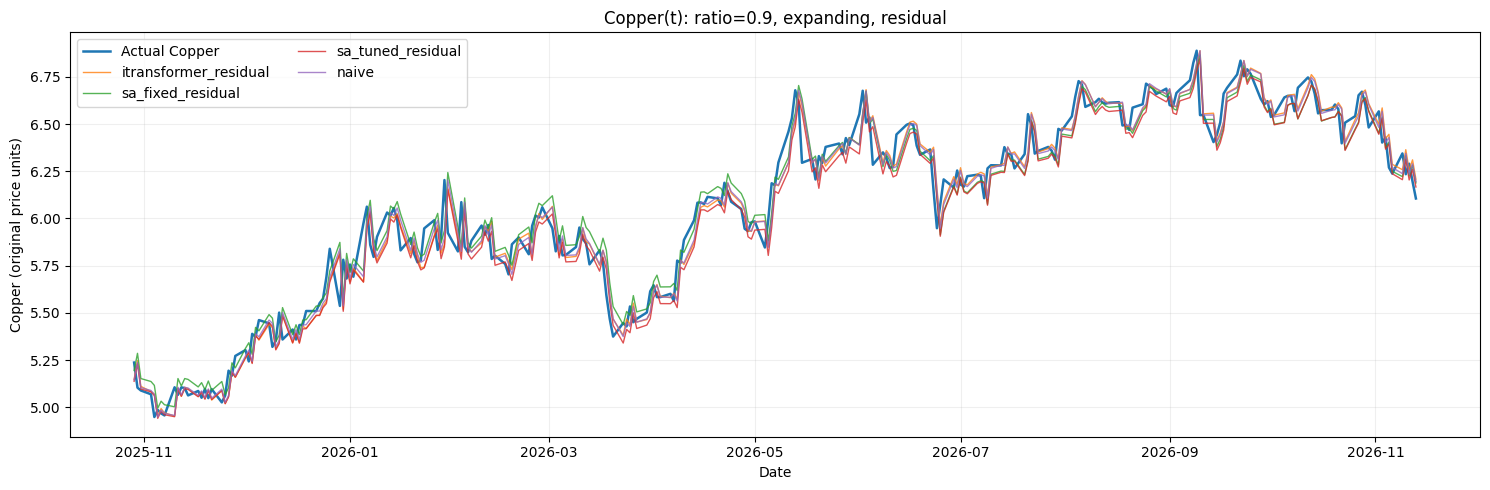

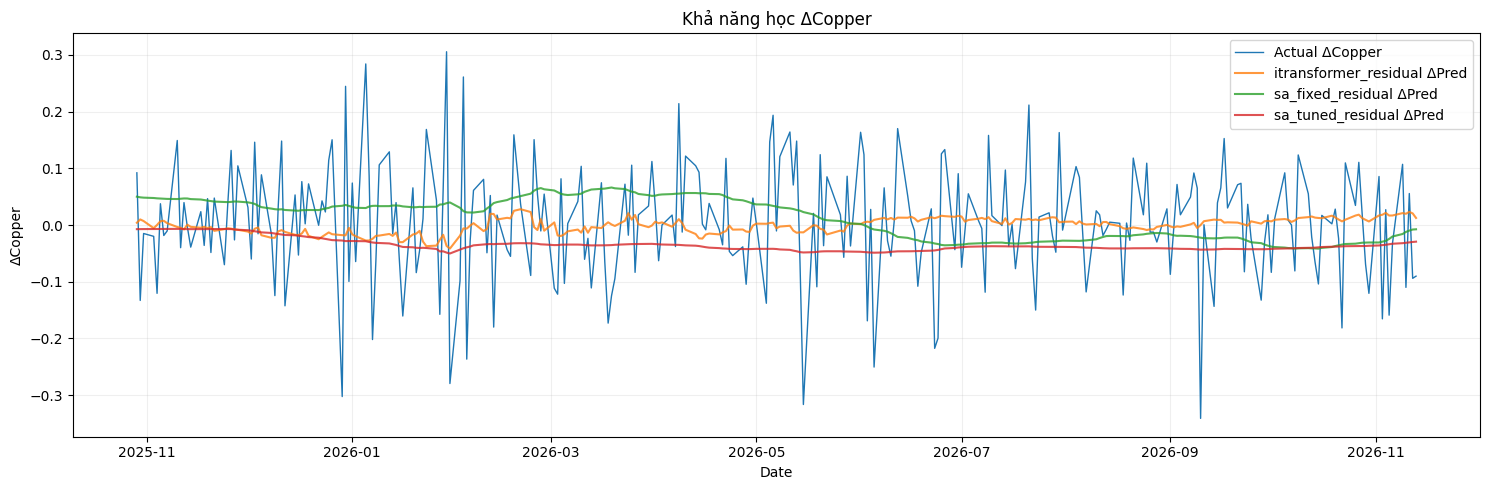

model                   itransformer_direct  itransformer_residual     naive  \
ratio scheme                                                                   
0.800 expanding                    1.264259               0.068855  0.069001   
      recency_weighted             1.277163               0.069000  0.069001   
      rolling_756                  1.395136               0.069346  0.069001   
0.900 expanding                    1.768602               0.078119  0.077077   
      recency_weighted             1.823129               0.077198  0.077077   
      rolling_756                  1.198720               0.077859  0.077077   
0.925 expanding                    1.877288               0.075127  0.075116   
      recency_weighted             1.639274               0.075680  0.075116   
      rolling_756                  1.677452               0.075492  0.075116   
0.950 expanding                    1.926325               0.072626  0.072799   
      recency_weighted             1.969447               0.075362  0.072799   
      rolling_756                  1.660730               0.073378  0.072799   

model                   sa_fixed_direct  sa_fixed_residual  sa_tuned_direct  \
ratio scheme                                                                  
0.800 expanding                0.775273           0.101586         0.777634   
      recency_weighted         0.711935           0.102047         0.718494   
      rolling_756              1.154500           0.117236         1.545358   
0.900 expanding                0.798291           0.082928         0.562087   
      recency_weighted         0.715643           0.084190         0.813393   
      rolling_756              0.999288           0.080745         0.950112   
0.925 expanding                0.803243           0.085332         0.778423   
      recency_weighted         0.683179           0.087864         0.992546   
      rolling_756              1.131303           0.084011         1.147128   
0.950 expanding                0.869241           0.097411         0.766455   
      recency_weighted         0.729674           0.099170         0.845762   
      rolling_756              1.097936           0.082562         0.862095   

model                   sa_tuned_residual  
ratio scheme                               
0.800 expanding                  0.070461  
      recency_weighted           0.077382  
      rolling_756                0.090753  
0.900 expanding                  0.085346  
      recency_weighted           0.081356  
      rolling_756                0.094720  
0.925 expanding                  0.075359  
      recency_weighted           0.075464  
      rolling_756                0.077167  
0.950 expanding                  0.072993  
      recency_weighted           0.072504  
      rolling_756                0.080267

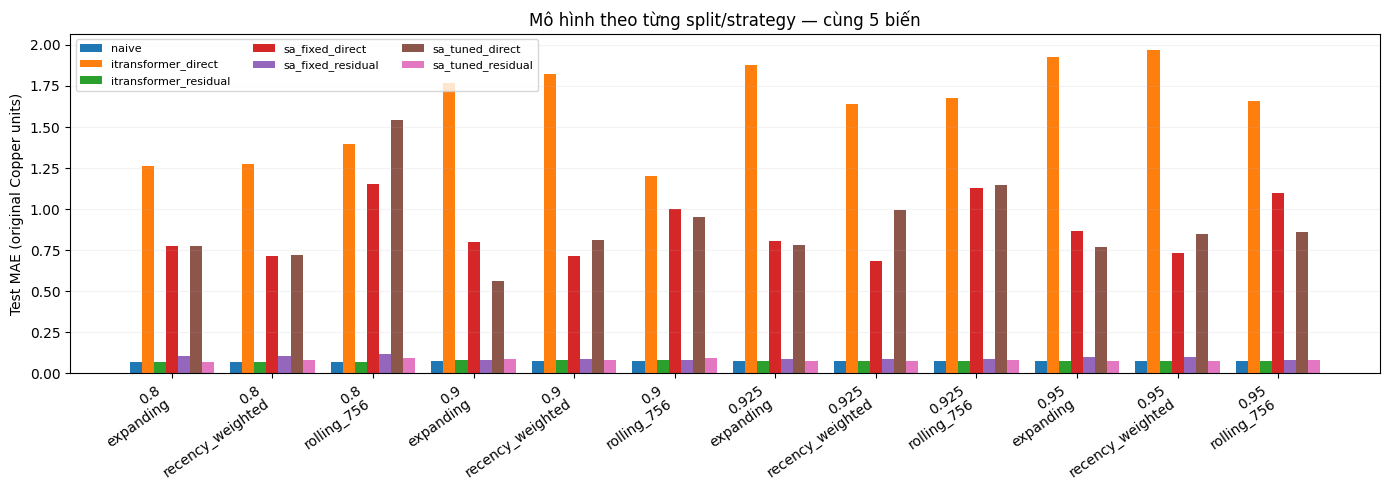

In [11]:
PLOT_RATIO=0.90 if 0.90 in RATIOS else RATIOS[0]
PLOT_SCHEME='expanding'
PLOT_OBJECTIVE='residual'
models=[f'itransformer_{PLOT_OBJECTIVE}',f'sa_fixed_{PLOT_OBJECTIVE}',
        f'sa_tuned_{PLOT_OBJECTIVE}','naive']
sub=grid_preds[(np.isclose(grid_preds.ratio,PLOT_RATIO))&
               (grid_preds.scheme==PLOT_SCHEME)&(grid_preds.model.isin(models))].copy()
if not sub.empty:
    fig,ax=plt.subplots(figsize=(15,5))
    actual=sub[sub.model==models[0]].sort_values('Date')
    ax.plot(actual.Date,actual.actual,label='Actual Copper',linewidth=1.8)
    for m in models:
        p=sub[sub.model==m].sort_values('Date')
        ax.plot(p.Date,p.pred,label=m,alpha=.8,linewidth=1.0)
    ax.set(title=f'Copper(t): ratio={PLOT_RATIO:g}, {PLOT_SCHEME}, {PLOT_OBJECTIVE}',
           xlabel='Date',ylabel='Copper (original price units)')
    ax.legend(ncol=2);ax.grid(alpha=.2);fig.tight_layout()
    fig.savefig(OUT/'figures'/'actual_pred_vs_naive.png',dpi=160)
    plt.show()

    fig,ax=plt.subplots(figsize=(15,5))
    ax.plot(actual.Date,actual.actual_delta,label='Actual ΔCopper',linewidth=1)
    for m in models[:-1]:
        p=sub[sub.model==m].sort_values('Date')
        ax.plot(p.Date,p.pred_delta,label=f'{m} ΔPred',alpha=.8)
    ax.set(title='Khả năng học ΔCopper',xlabel='Date',ylabel='ΔCopper')
    ax.legend();ax.grid(alpha=.2);fig.tight_layout()
    fig.savefig(OUT/'figures'/'delta_predictions.png',dpi=160)
    plt.show()

pivot=grid.pivot_table(index=['ratio','scheme'],columns='model',values='mae',aggfunc='first')
display(pivot.round(6))
fig,ax=plt.subplots(figsize=(14,5))
inds=np.arange(len(pivot));width=.12
for j,m in enumerate(MODEL_NAMES):
    ax.bar(inds+(j-3)*width,pivot[m].to_numpy(),width,label=m)
ax.set_xticks(inds,[f'{r:g}\n{s}' for r,s in pivot.index],rotation=35,ha='right')
ax.set_ylabel('Test MAE (original Copper units)')
ax.set_title('Mô hình theo từng split/strategy — cùng 5 biến')
ax.legend(ncol=3,fontsize=8);ax.grid(alpha=.15,axis='y');fig.tight_layout()
fig.savefig(OUT/'figures'/'mae_all_models.png',dpi=150)
plt.show()


## 10. Manifest / xuất ZIP / tiêu chí báo cáo

Khi hoàn tất, đọc `grid_results.csv`, `paired_comparison.csv`, `paired_hac_tests.csv`, `validation_winner.csv`, `grid_predictions.csv`, `sa_best_hp.json`, `sa_trials_*.csv`. ZIP mặc định **không nhúng weights** để gọn; weights `.keras` nằm tại từng `jobs/.../model.keras` trong Drive. `missing_jobs.json` phải là `[]`.


In [12]:
manifest={
 'project':'iTransformer_vs_SA-LSTM_K5_Fair_Colab',
 'created_at':time.strftime('%Y-%m-%d %H:%M:%S'),
 'data_path':str(data_path),'data_sha256':csv_sha256,
 'n_rows':int(len(data)),'range':[str(data.Date.min().date()),str(data.Date.max().date())],
 'features':FEATURES,'note':'Copper_history is past Copper only, NOT future Copper(t)',
 'ratio_scheme_count':len(RATIOS)*len(SCHEMES),
 'expected_jobs':len(expected_jobs()),'completed_jobs':len(grid),
 'complete':len(missing)==0,'missing_jobs':missing,
 'sa_best_hp_by_objective':sa_best,
 'sa_dropout_layout':SA_DROPOUT_LAYOUT,
 'it_epochs_max':EPOCHS,'sa_epochs_max':EPOCHS,
 'run_key':RUN_KEY,'tensorflow':tf.__version__,
 'interpretation':'Compare within each ratio/scheme/objective. Multiple tests overlap.'
}
atomic_json(manifest,OUT/'manifest.json')
REPORT_ZIP=OUT/'iTransformer_vs_SA_LSTM_K5_FINAL_Results.zip'
with zipfile.ZipFile(REPORT_ZIP,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as zf:
    for p in sorted(OUT.rglob('*')):
        if not p.is_file() or p==REPORT_ZIP or p.suffix=='.tmp': continue
        if p.suffix=='.keras' and not INCLUDE_MODELS_IN_ZIP: continue
        zf.write(p,p.relative_to(OUT))
print('ALL JOBS:',len(grid),'/',len(expected_jobs()),'| COMPLETE:',len(missing)==0)
print('Run folder:',OUT)
print('Final results ZIP:',REPORT_ZIP)
print('CSV main:',OUT/'grid_results.csv')
print('Pairwise comparisons:',OUT/'paired_comparison.csv')
print('SA best HP:',OUT/'sa_best_hp.json')
print('Dataset SHA256:',csv_sha256)
if IN_COLAB and AUTO_DOWNLOAD_ZIP:
    from google.colab import files
    files.download(str(REPORT_ZIP))


ALL JOBS: 84 / 84 | COMPLETE: True
Run folder: /content/drive/MyDrive/Copper_iTransformer_vs_SA_LSTM_K5_Fair/itransformer_vs_sa_lstm/FULL_MODE_K5_lb22_s42_dataa761a908_cfgd1b751120e44
Final results ZIP: /content/drive/MyDrive/Copper_iTransformer_vs_SA_LSTM_K5_Fair/itransformer_vs_sa_lstm/FULL_MODE_K5_lb22_s42_dataa761a908_cfgd1b751120e44/iTransformer_vs_SA_LSTM_K5_FINAL_Results.zip
CSV main: /content/drive/MyDrive/Copper_iTransformer_vs_SA_LSTM_K5_Fair/itransformer_vs_sa_lstm/FULL_MODE_K5_lb22_s42_dataa761a908_cfgd1b751120e44/grid_results.csv
Pairwise comparisons: /content/drive/MyDrive/Copper_iTransformer_vs_SA_LSTM_K5_Fair/itransformer_vs_sa_lstm/FULL_MODE_K5_lb22_s42_dataa761a908_cfgd1b751120e44/paired_comparison.csv
SA best HP: /content/drive/MyDrive/Copper_iTransformer_vs_SA_LSTM_K5_Fair/itransformer_vs_sa_lstm/FULL_MODE_K5_lb22_s42_dataa761a908_cfgd1b751120e44/sa_best_hp.json
Dataset SHA256: a761a9082de36ad8724597ff1518e24bbf1a61676bd3164676e7f4218d275d83


## Checklist trước khi viết kết luận khoa học

1. [ ] Chạy `FULL_MODE`, thấy **84/84 jobs** (72 deep fits + 12 Naive), `missing_jobs=[]` và cả hai SA search đủ trial.
2. [ ] Bảo đảm so **DIRECT với DIRECT**, **RESIDUAL với RESIDUAL**; không kết luận Transformer tốt hơn LSTM chỉ nhờ residual learning.
3. [ ] So sánh với **Naive** bằng MAE, MAE skill, Directional Accuracy và phân phối `Δpred`. Kiểm tra model có rơi vào hiện tượng gần-persistence không.
4. [ ] Ghi rõ trong báo cáo **Dropout thứ hai sau Dense theo hình**; nếu chuyển sang `notebook_v22` thì là mô hình khác. Nếu công bố Fixed 39/111, không gọi đó là nghiệm tối ưu SA.
5. [ ] SA search trên validation 80/20 trước test; mọi scaler từng run fit train-only. **Khung thời gian test chồng lấn**, chỉ dùng bảng theo từng split; nên bổ sung nhiều seed và walk-forward tách biệt để kiểm tra độ bền.
6. [ ] Cùng 5 biến và cùng cửa sổ chưa đảm bảo khả năng giao dịch thực tế vì **thời điểm công bố giá** giữa 5 thị trường có thể khác nhau; cần kiểm chứng nếu dùng bài toán dự báo thời gian thực.

**Nguồn thiết kế:** notebook SA-LSTM V22 đã upload và notebook iTransformer V20 đã có trong cuộc trò chuyện. Không gán sẵn bất kỳ số liệu kết quả nào.
